# 04 · Analyse et présentation (rendu final)

**Question :** comment le trafic évolue-t-il selon l'heure et le jour sur `Bd_Richard_Lenoir`, `Av_Ledru_Rollin` et `Bd_Gal_Martial_Valin`, de mars à août 2026 ?

Chaque graphique est suivi de **chiffres calculés** (cellule de code) et d'une aide à la lecture. À la fin, réécrivez les conclusions avec vos mots dans le README.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
df = pd.read_pickle("data/processed/comptages_transformes.pkl")
df["axe"] = df["axe"].astype(str)
JOURS = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
Path("figures").mkdir(exist_ok=True)
print(df.shape, "|", df["axe"].unique().tolist())

(102627, 28) | ['Bd_Gal_Martial_Valin', 'Bd_Richard_Lenoir', 'Av_Ledru_Rollin']


## 1. Évolution du trafic selon l'heure : jours ouvrés vs week-ends
On calcule le débit moyen pour chaque heure, séparément pour les jours ouvrés et les week-ends / jours fériés.

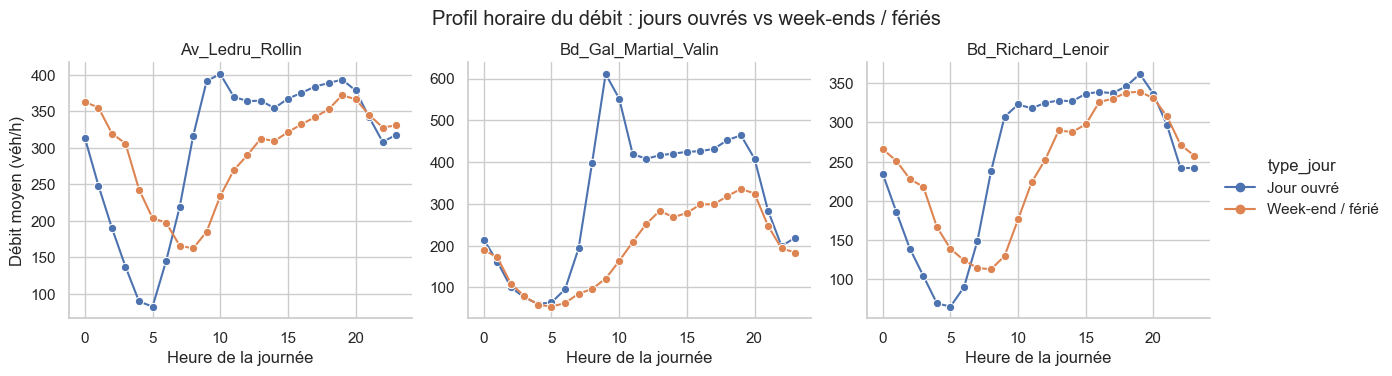

In [2]:
profil = (df.groupby(["axe", "type_jour", "heure"], observed=True)["q_net"].mean().reset_index())
g = sns.relplot(data=profil, x="heure", y="q_net", hue="type_jour", col="axe",
                kind="line", marker="o", height=3.6, aspect=1.15, facet_kws={"sharey": False})
g.set_axis_labels("Heure de la journée", "Débit moyen (véh/h)")
g.set_titles("{col_name}")
g.figure.suptitle("Profil horaire du débit : jours ouvrés vs week-ends / fériés", y=1.04)
g.savefig("figures/profil_horaire.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
for axe, d in profil.groupby("axe"):
    ouvre = d[d["type_jour"] == "Jour ouvré"].set_index("heure")["q_net"]
    we = d[d["type_jour"] != "Jour ouvré"].set_index("heure")["q_net"]
    print(f"{axe}: pointe jour ouvré à {ouvre.idxmax()} h ({ouvre.max():.0f} véh/h) ; "
          f"pointe week-end à {we.idxmax()} h ({we.max():.0f} véh/h) ; "
          f"trafic moyen week-end = {we.mean() / ouvre.mean():.0%} du trafic en semaine.")

Av_Ledru_Rollin: pointe jour ouvré à 10 h (401 véh/h) ; pointe week-end à 19 h (372 véh/h) ; trafic moyen week-end = 97% du trafic en semaine.
Bd_Gal_Martial_Valin: pointe jour ouvré à 9 h (611 véh/h) ; pointe week-end à 19 h (336 véh/h) ; trafic moyen week-end = 62% du trafic en semaine.
Bd_Richard_Lenoir: pointe jour ouvré à 19 h (362 véh/h) ; pointe week-end à 19 h (339 véh/h) ; trafic moyen week-end = 96% du trafic en semaine.


**Comment lire :** en semaine, des **pics** (matin et soir) traduisent les trajets domicile-travail ; le week-end, la courbe est plus **plate et décalée** vers le milieu de journée. Le rapport « week-end / semaine » dit de combien le trafic baisse quand les gens ne travaillent pas.

> ✍️ Reprenez les chiffres imprimés et dites quel axe est le plus « pendulaire » (grand écart pointe / creux en semaine).

## 2. Heatmap jour × heure
Le débit moyen pour chaque combinaison (jour de la semaine, heure) : 7 × 24 cases par axe.

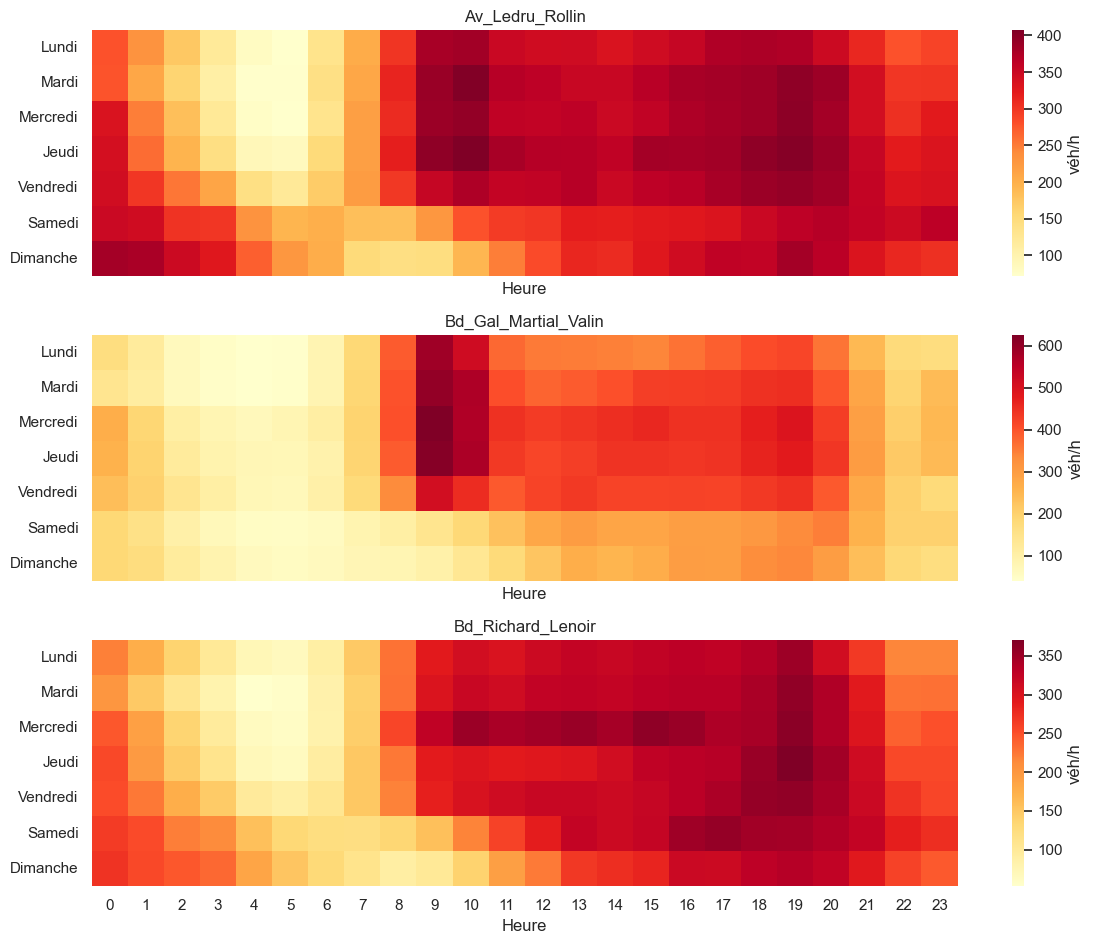

In [4]:
axes_liste = sorted(df["axe"].unique())
fig, axs = plt.subplots(len(axes_liste), 1, figsize=(12, 3.2 * len(axes_liste)), sharex=True)
axs = np.atleast_1d(axs)
for ax, axe in zip(axs, axes_liste):
    pivot = (df[df["axe"] == axe].pivot_table(index="nom_jour", columns="heure", values="q_net",
                                              aggfunc="mean", observed=True).reindex(JOURS))
    sns.heatmap(pivot, cmap="YlOrRd", ax=ax, cbar_kws={"label": "véh/h"})
    ax.set(title=axe, xlabel="Heure", ylabel="")
plt.tight_layout()
plt.savefig("figures/heatmap_jour_heure.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
for axe in axes_liste:
    pivot = (df[df["axe"] == axe].pivot_table(index="nom_jour", columns="heure", values="q_net",
                                              aggfunc="mean", observed=True))
    j, h = pivot.stack().idxmax()
    j2, h2 = pivot.stack().idxmin()
    print(f"{axe}: case la plus chargée = {j} à {h} h ({pivot.loc[j, h]:.0f} véh/h) ; "
          f"la plus calme = {j2} à {h2} h ({pivot.loc[j2, h2]:.0f} véh/h).")

Av_Ledru_Rollin: case la plus chargée = Jeudi à 10 h (407 véh/h) ; la plus calme = Lundi à 5 h (71 véh/h).
Bd_Gal_Martial_Valin: case la plus chargée = Mercredi à 9 h (625 véh/h) ; la plus calme = Mardi à 4 h (40 véh/h).
Bd_Richard_Lenoir: case la plus chargée = Jeudi à 19 h (370 véh/h) ; la plus calme = Mardi à 4 h (53 véh/h).


**Comment lire :** les zones foncées sont les créneaux les plus chargés. Des bandes verticales sombres le matin et le soir sur les 5 premières lignes = heures de pointe ouvrées ; si le samedi diffère du dimanche (plus de trafic l'après-midi), c'est l'effet des courses et des loisirs.

## 3. Diagramme fondamental : débit vs occupation
Relation théorique : à faible occupation, plus de véhicules = plus de débit ; au-delà d'un seuil (capacité), le trafic se congestionne, l'occupation continue de monter mais le **débit redescend**.

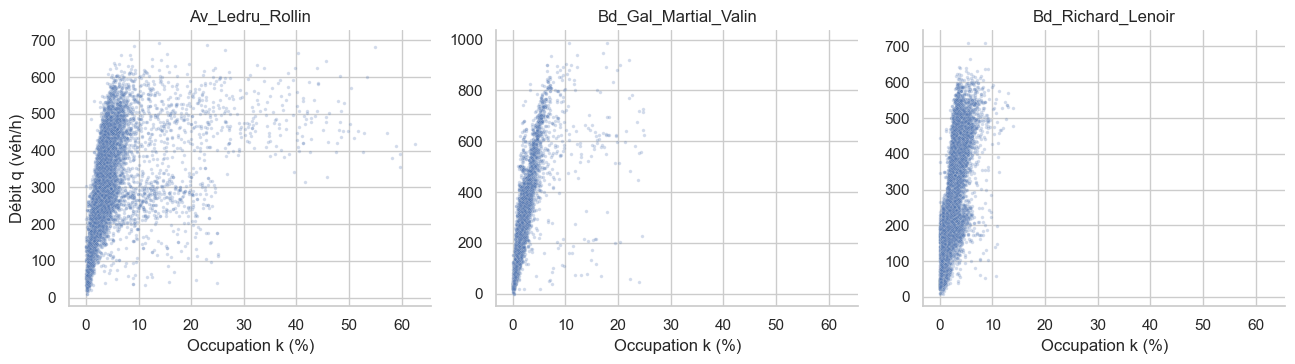

In [6]:
ech = df.dropna(subset=["q_net", "k_net"]).groupby("axe", group_keys=False).sample(frac=0.25, random_state=1)
g = sns.relplot(data=ech, x="k_net", y="q_net", col="axe", kind="scatter", s=6, alpha=.25,
                height=3.8, aspect=1.15, facet_kws={"sharey": False})
g.set_axis_labels("Occupation k (%)", "Débit q (véh/h)")
g.set_titles("{col_name}")
g.savefig("figures/diagramme_fondamental.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
d = df.dropna(subset=["q_net", "k_net"]).copy()
d["k_tranche"] = pd.cut(d["k_net"], bins=range(0, 105, 5))
for axe, sub in d.groupby("axe"):
    med = sub.groupby("k_tranche", observed=True)["q_net"].median()
    top = med.idxmax()
    print(f"{axe}: débit médian maximal ({med.max():.0f} véh/h) pour une occupation de {top.left:.0f} à {top.right:.0f} %. "
          f"Corrélation q-k : {sub['q_net'].corr(sub['k_net']):.2f}.")

Av_Ledru_Rollin: débit médian maximal (502 véh/h) pour une occupation de 40 à 45 %. Corrélation q-k : 0.45.
Bd_Gal_Martial_Valin: débit médian maximal (677 véh/h) pour une occupation de 5 à 10 %. Corrélation q-k : 0.70.
Bd_Richard_Lenoir: débit médian maximal (466 véh/h) pour une occupation de 10 à 15 %. Corrélation q-k : 0.73.


**Comment lire :** le nuage monte en forme de « cloche » : la montée correspond au trafic fluide, le sommet à la capacité du tronçon, et la décroissance (si elle existe dans vos données) à la congestion. Si le nuage reste presque linéaire jusqu'à des occupations élevées, le tronçon n'atteint jamais de vraie saturation sur la période. Une corrélation positive forte confirme que `q` et `k` évoluent ensemble en régime fluide.

## 4. Évolution sur les six mois

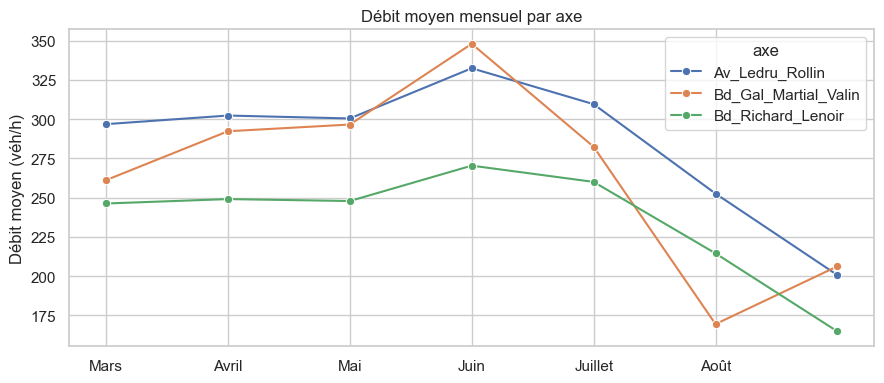

In [8]:
mens = df.groupby(["axe", "mois"], observed=True)["q_net"].mean().reset_index()
plt.figure(figsize=(9, 4))
sns.lineplot(data=mens, x="mois", y="q_net", hue="axe", marker="o")
plt.xticks(range(3, 9), ["Mars", "Avril", "Mai", "Juin", "Juillet", "Août"])
plt.xlabel(""); plt.ylabel("Débit moyen (véh/h)"); plt.title("Débit moyen mensuel par axe")
plt.tight_layout(); plt.savefig("figures/evolution_mensuelle.png", dpi=150); plt.show()

In [9]:
piv = mens.pivot(index="mois", columns="axe", values="q_net")
print(piv.round(0))
print()
for axe in piv.columns:
    print(f"{axe}: août = {piv.loc[8, axe] / piv.loc[6, axe] - 1:+.1%} par rapport à juin ; "
          f"mois le plus chargé = {piv[axe].idxmax()}, le plus calme = {piv[axe].idxmin()}.")

axe   Av_Ledru_Rollin  Bd_Gal_Martial_Valin  Bd_Richard_Lenoir
mois                                                          
3               297.0                 261.0              246.0
4               302.0                 292.0              249.0
5               300.0                 297.0              248.0
6               332.0                 348.0              270.0
7               310.0                 282.0              260.0
8               253.0                 169.0              214.0
9               201.0                 206.0              165.0

Av_Ledru_Rollin: août = -24.0% par rapport à juin ; mois le plus chargé = 6, le plus calme = 9.
Bd_Gal_Martial_Valin: août = -51.3% par rapport à juin ; mois le plus chargé = 6, le plus calme = 8.
Bd_Richard_Lenoir: août = -20.7% par rapport à juin ; mois le plus chargé = 6, le plus calme = 9.


**Comment lire :** une baisse en juillet-août par rapport à mai-juin reflète les vacances d'été (Parisiens partis). Attention : moins de trafic ne veut pas dire moins de congestion si la baisse touche surtout les heures de pointe.

## 5. Résultats clés (à reprendre dans le README)

In [10]:
lignes = []
for axe in axes_liste:
    sub = df[df["axe"] == axe]
    ouvre = sub[sub["type_jour"] == "Jour ouvré"].groupby("heure")["q_net"].mean()
    we = sub[sub["type_jour"] != "Jour ouvré"]["q_net"].mean()
    m = sub.groupby("mois")["q_net"].mean()
    lignes.append({"axe": axe, "q_moyen": sub["q_net"].mean(), "heure_pointe_ouvre": ouvre.idxmax(),
                   "q_pointe": ouvre.max(), "week-end_vs_semaine": we / sub[sub["type_jour"] == "Jour ouvré"]["q_net"].mean() - 1,
                   "aout_vs_juin": m[8] / m[6] - 1,
                   "part_k_>_30%": (sub["k_net"] > 30).mean()})
resume = pd.DataFrame(lignes).set_index("axe")
resume.round(3)

,q_moyen,heure_pointe_ouvre,q_pointe,week-end_vs_semaine,aout_vs_juin,part_k_>_30%
axe,,,,,,
Av_Ledru_Rollin,298.452,10,401.109,-0.033,-0.240,0.015
Bd_Gal_Martial_Valin,274.305,9,610.872,-0.374,-0.513,0.000
Bd_Richard_Lenoir,247.836,19,361.691,-0.042,-0.207,0.000


In [11]:
resume.to_csv("results/resume_par_axe.csv", encoding="utf-8-sig")
for axe, r in resume.iterrows():
    print(f"- {axe} : {r['q_moyen']:.0f} véh/h en moyenne ; pointe en semaine à {int(r['heure_pointe_ouvre'])} h "
          f"({r['q_pointe']:.0f} véh/h) ; week-end {r['week-end_vs_semaine']:+.0%} vs semaine ; "
          f"août {r['aout_vs_juin']:+.0%} vs juin ; occupation > 30 % sur {r['part_k_>_30%']:.1%} des heures.")

- Av_Ledru_Rollin : 298 véh/h en moyenne ; pointe en semaine à 10 h (401 véh/h) ; week-end -3% vs semaine ; août -24% vs juin ; occupation > 30 % sur 1.5% des heures.
- Bd_Gal_Martial_Valin : 274 véh/h en moyenne ; pointe en semaine à 9 h (611 véh/h) ; week-end -37% vs semaine ; août -51% vs juin ; occupation > 30 % sur 0.0% des heures.
- Bd_Richard_Lenoir : 248 véh/h en moyenne ; pointe en semaine à 19 h (362 véh/h) ; week-end -4% vs semaine ; août -21% vs juin ; occupation > 30 % sur 0.0% des heures.


## 6. Limites
- Les capteurs sont des boucles dans la chaussée : ils comptent des véhicules, pas des personnes, et un tronçon n'est pas représentatif de tout l'axe.
- Six mois seulement : pas de saisonnalité annuelle, et les jours fériés sont traités à part mais pas les ponts ni les grèves.
- Les valeurs manquantes ne sont pas aléatoires (certains capteurs sont en panne) : les moyennes ignorent ces heures.
- Aucune donnée météo ni événementielle : on décrit, on n'explique pas les écarts.